# Análise descritiva evolutiva
Como a base de dados muda a cada etapa do projeto, dos valores do PDF à base completa:
1. **Brutos** (`data/processed/brutos_prontos.xlsx`): os valores do PDF do SEMAE, com as 3 estatísticas de cada mês (mínimo, média e máximo); 192 meses e 24 variáveis.
2. **Limpos** (`dados_limpos.xlsx`, notebook `processamento`): os textos (ex.: "<0,001") viram NaN, sai o mês sem nenhum valor (2024-12) e saem as variáveis com mais de 30% de faltantes.
3. **Tratada** (`dados_med_tratados.xlsx`, notebook `outliers`): só a média; os valores tratados como outliers viram NaN.
4. **Imputada**, de dois jeitos (gerada aqui): o KNN padronizado em todas as variáveis e a regra do pipeline (média ou KNN, conforme a fração de faltantes de cada variável).

Mín e Máx entram só nas tabelas, e só nos brutos e nos limpos (não são tratados nem imputados). As figuras usam a média.

# Set Up

In [1]:
import warnings
import pandas as pd
from pcj.utils import dados, BASE_DIR, separar_colunas
from pcj.processamento import decompor_estatisticas
from pcj.imputacao import mean_imput, knn_imput
from pcj.analise_descritiva import analise_descritiva
from pcj.visualizacoes import visualizacoes_missingno, faltantes_ano, series_marcadas, boxplots_bases

In [2]:
# Brutos: a primeira coluna do arquivo é o número da linha e vira o índice (como no notebook processamento)
brutos = pd.read_excel(BASE_DIR / "data" / "processed" / "brutos_prontos.xlsx", index_col=0)
_, variaveis_brutos = separar_colunas(brutos)

# Limpos e tratada
limpos, _, variaveis = dados(r"data\processed\dados_limpos.xlsx")
tratada, _, _ = dados(r"data\processed\dados_med_tratados.xlsx")

# Casas decimais de cada variável nos dados originais, para a analise_descritiva formatar os números
# (com original=True, a dados devolve também esse dicionário)
_, _, _, casas_decimais = dados(r"data\raw\dados_brutos.xlsx", original=True)

print("Brutos:", brutos.shape, "| limpos:", limpos.shape, "| tratada:", tratada.shape)
print("Variáveis: brutos", len(variaveis_brutos), "| limpos e tratada", len(variaveis))

Brutos: (576, 27) | limpos: (573, 20) | tratada: (191, 20)
Variáveis: brutos 24 | limpos e tratada 16


# Imputação: a base completa
Até aqui, a imputação só tinha sido avaliada (notebooks `imputacoes_*`). Aqui ela preenche as células vazias da tratada (as que já faltavam e as dos valores tratados), de dois jeitos:
- **KNN padronizado em todas as variáveis:** o k e os pesos escolhidos no notebook `imputacoes_mesma_prova_tratados` (lidos do Excel dele). `min_missing=0` e `max_missing=1` fazem a `knn_imput` aceitar todas as variáveis.
- **Regra do pipeline:** a `mean_imput` nas variáveis com até 5% de faltantes e a `knn_imput` com os padrões (k = 2, pesos iguais, sem padronizar) nas de 5 a 30%, como o projeto previa (é o desenho do A original, notebook `imputacoes_outliers_tratados`).

In [3]:
# k e pesos escolhidos no imputacoes_mesma_prova_tratados: a mesma conta de lá
# (pivot: uma linha por (k, pesos), uma coluna por taxa; o maior R² médio na média das 4 taxas)
escolha_k = pd.read_excel(BASE_DIR / "data" / "output" / "imputacoes_mesma_prova_tratados.xlsx", sheet_name="escolha_k")
tabela_escolha = escolha_k.pivot(index=["k", "pesos"], columns="pct_faltantes", values="r2_medio")
k_escolhido, pesos_escolhidos = tabela_escolha.mean(axis=1).idxmax()
print("KNN: k =", k_escolhido, "| pesos =", pesos_escolhidos)

# 1. KNN padronizado em todas as variáveis
imputada_knn = knn_imput(tratada, min_missing=0, max_missing=1, n_neighbors=int(k_escolhido),
                         weights=pesos_escolhidos, padronizar=True)

# 2. Regra do pipeline: a média preenche as variáveis com até 5% de faltantes; depois, o KNN
#    (padrões da knn_imput) preenche as de 5 a 30%. As da média já não têm faltantes e ficam fora do KNN
imputada_pipeline = knn_imput(mean_imput(tratada))

# Que método o pipeline usou em cada variável (fração de faltantes na tratada)
fracao = tratada[variaveis].isna().mean()
print("Pipeline, média:", fracao[fracao <= 0.05].index.tolist())
print("Pipeline, KNN:", fracao[fracao > 0.05].index.tolist())

KNN: k = 13 | pesos = distance
Pipeline, média: ['COR', 'TURB.', 'pH', 'O.C.', 'O.D.', 'DUR.', 'Fe', 'Cond.']
Pipeline, KNN: ['ALC.', 'AC.', 'Cl', 'Mn', 'Cianobacteria', 'C.F.', 'Clorofila', 'F']


Conferências: nenhuma célula vazia nas bases imputadas, e os valores observados (os que a tratada já tinha) iguais aos da tratada.

In [4]:
# Células vazias na tratada: as que a imputação preenche
vazias_tratada = tratada[variaveis].isna()
print("Células vazias na tratada:", vazias_tratada.sum().sum())

for nome_base, base in [("KNN", imputada_knn), ("pipeline", imputada_pipeline)]:
    # where mantém o valor onde a condição é True e põe NaN no resto: aqui, só os observados.
    # A diferença compara os valores (o equals compararia também o tipo da coluna: a knn_imput
    # padronizada devolve tudo como float, e na tratada o TURB. é inteiro)
    observados_base = base[variaveis].where(~vazias_tratada)
    observados_tratada = tratada[variaveis].where(~vazias_tratada)
    print(f"{nome_base}: células vazias {base[variaveis].isna().sum().sum()} | maior diferença nos observados:",
          (observados_base - observados_tratada).abs().max().max())

Células vazias na tratada: 185
KNN: células vazias 0 | maior diferença nos observados: 0.0
pipeline: células vazias 0 | maior diferença nos observados: 0.0


Os valores preenchidos em cada variável: a mediana dos preenchidos por cada imputação, ao lado da mediana dos valores observados (na tratada), como referência.

In [5]:
linhas = []
for variavel in variaveis:
    vazias = vazias_tratada[variavel]
    linhas.append({
        "variavel": variavel,
        "preenchidas": vazias.sum(),
        "metodo_no_pipeline": "média" if fracao[variavel] <= 0.05 else "KNN",
        "mediana_observada": tratada[variavel].median(),
        "mediana_knn": imputada_knn.loc[vazias, variavel].median(),
        "mediana_pipeline": imputada_pipeline.loc[vazias, variavel].median()
    })

pd.DataFrame(linhas).round(3)

,variavel,preenchidas,metodo_no_pipeline,mediana_observada,mediana_knn,mediana_pipeline
0,COR,1,média,77.000,344.508,116.911
1,TURB.,0,média,28.000,NaN,NaN
2,pH,3,média,7.300,7.478,7.315
3,ALC.,13,KNN,57.000,65.982,75.000
4,AC.,12,KNN,10.000,11.567,8.500
5,O.C.,8,média,8.100,7.639,8.360
6,O.D.,5,média,3.100,2.817,3.133
7,Cl,12,KNN,38.000,42.445,55.500
8,DUR.,7,média,50.000,56.888,53.462
9,Fe,7,média,1.390,1.303,2.086


# Bases de cada etapa
Uma entrada por base × estatística. Os brutos e os limpos têm as 3 estatísticas (`decompor_estatisticas`); a tratada e as imputadas, só a média. A última posição diz qual é a etapa anterior (com a mesma estatística), para medir o que mudou de uma para a outra.

In [6]:
# Cada item: (base, estatística, tabela, etapa anterior). Os brutos não têm etapa anterior (None)
bases = []
for estatistica in ["min", "med", "max"]:
    bases.append(("brutos", estatistica, decompor_estatisticas(brutos, estatistica=estatistica), None))
for estatistica in ["min", "med", "max"]:
    bases.append(("limpos", estatistica, decompor_estatisticas(limpos, estatistica=estatistica), "brutos"))
bases.append(("tratada", "med", tratada, "limpos"))
bases.append(("imputada (KNN)", "med", imputada_knn, "tratada"))
bases.append(("imputada (pipeline)", "med", imputada_pipeline, "tratada"))

# Para achar a tabela da etapa anterior pelo nome e pela estatística
por_nome = {}
for nome_base, estatistica, tabela, anterior in bases:
    por_nome[(nome_base, estatistica)] = tabela

# Resumo por etapa
Uma linha por base × estatística:
- **meses** e **variáveis**: o tamanho da base; **células** = meses × variáveis;
- **faltantes**: células vazias, em número e em % das células;
- **textos**: células com texto no lugar do número (ex.: "<0,001"), que a limpeza transforma em NaN;
- **meses completos**: meses com número em todas as variáveis;
- em relação à etapa anterior (mesma estatística): **meses que saíram**, **variáveis que saíram**, **viraram NaN** (tinham valor e ficaram vazias: textos na limpeza, outliers no tratamento) e **preenchidas** (estavam vazias e ganharam valor: a imputação). As duas últimas olham só os meses e as variáveis que as duas etapas têm, com os meses casados pela data.

In [7]:
linhas = []
for nome_base, estatistica, tabela, anterior in bases:
    _, variaveis_base = separar_colunas(tabela)

    # A data vira o índice (set_index), para casar os meses com a etapa anterior
    valores = tabela.set_index("Data")[variaveis_base]

    # Os valores como número: o que for texto vira NaN (errors="coerce"), só para contar
    numeros = valores.apply(pd.to_numeric, errors="coerce")
    vazias = valores.isna()
    textos = numeros.isna() & ~vazias

    linha = {
        "base": nome_base,
        "estatistica": estatistica,
        "meses": len(valores),
        "variaveis": len(variaveis_base),
        "celulas": vazias.size,
        "faltantes": vazias.sum().sum(),
        "pct_faltantes": 100 * vazias.sum().sum() / vazias.size,
        "textos": textos.sum().sum(),
        "meses_completos": numeros.notna().all(axis=1).sum()
    }

    if anterior is not None:
        tabela_anterior = por_nome[(anterior, estatistica)]
        _, variaveis_anterior = separar_colunas(tabela_anterior)
        valores_anterior = tabela_anterior.set_index("Data")[variaveis_anterior]

        linha["meses_que_sairam"] = len(valores_anterior) - len(valores)
        linha["variaveis_que_sairam"] = len(variaveis_anterior) - len(variaveis_base)

        # Só os meses e as variáveis que as duas etapas têm (intersection: o que está nos dois)
        meses_comuns = valores.index.intersection(valores_anterior.index)
        variaveis_comuns = [variavel for variavel in variaveis_base if variavel in variaveis_anterior]
        agora = valores.loc[meses_comuns, variaveis_comuns]
        antes = valores_anterior.loc[meses_comuns, variaveis_comuns]

        linha["viraram_nan"] = (antes.notna() & agora.isna()).sum().sum()
        linha["preenchidas"] = (antes.isna() & agora.notna()).sum().sum()

    linhas.append(linha)

# Nas linhas dos brutos, as colunas da etapa anterior ficam vazias (NaN)
resumo = pd.DataFrame(linhas)
resumo.round(2)

,base,estatistica,meses,variaveis,celulas,faltantes,pct_faltantes,textos,meses_completos,meses_que_sairam,variaveis_que_sairam,viraram_nan,preenchidas
0,brutos,min,192,24,4608,1535,33.31,1,0,NaN,NaN,NaN,NaN
1,brutos,med,192,24,4608,1534,33.29,1,0,NaN,NaN,NaN,NaN
2,brutos,max,192,24,4608,1534,33.29,2,0,NaN,NaN,NaN,NaN
3,limpos,min,191,16,3056,154,5.04,0,126,1.0,8.0,0.0,0.0
4,limpos,med,191,16,3056,153,5.01,0,126,1.0,8.0,0.0,0.0
5,limpos,max,191,16,3056,154,5.04,0,125,1.0,8.0,1.0,0.0
6,tratada,med,191,16,3056,185,6.05,0,118,0.0,0.0,32.0,0.0
7,imputada (KNN),med,191,16,3056,0,0.00,0,191,0.0,0.0,0.0,185.0
8,imputada (pipeline),med,191,16,3056,0,0.00,0,191,0.0,0.0,0.0,185.0


# Análise descritiva de cada base
O quadro da `analise_descritiva` para cada base × estatística: as estatísticas do `describe` (contagem, média, DP, mínimo, quartis, máximo) e os faltantes e os corrompidos (textos) de cada variável, com as casas decimais de cada variável nos dados originais. No Excel, os 9 quadros ficam numa aba só, com as colunas `base` e `estatistica` na frente.

In [8]:
quadros = []
for nome_base, estatistica, tabela, anterior in bases:
    metadados_base, variaveis_base = separar_colunas(tabela)

    # Casas decimais só das variáveis desta base (a formatar_variaveis percorre o dicionário inteiro)
    casas_base = {}
    for variavel in variaveis_base:
        casas_base[variavel] = casas_decimais[variavel]

    # A formatar_variaveis (chamada pela analise_descritiva) grava os números formatados, como texto,
    # em colunas de números, e o pandas avisa (FutureWarning) que isso vai dar erro numa versão futura,
    # uma vez por variável. catch_warnings + simplefilter escondem esse aviso só dentro do bloco with
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)
        quadro = analise_descritiva(tabela, metadados=metadados_base, variaveis=variaveis_base,
                                    n_casas_decimais=casas_base, salvar_arquivo=False)

    print(f"{nome_base}, {estatistica}")
    display(quadro)

    # Para o Excel: o nome de cada linha (variável ou metadado) vira a coluna "coluna" (reset_index),
    # e a base e a estatística entram nas duas primeiras posições (insert)
    quadro = quadro.reset_index(names="coluna")
    quadro.insert(0, "base", nome_base)
    quadro.insert(1, "estatistica", estatistica)
    quadros.append(quadro)

# concat empilha os 9 quadros numa tabela só
analise = pd.concat(quadros, ignore_index=True)

brutos, min


,count,unique,top,freq,mean,min,25%,50%,75%,max,std,Porcentagem de Dados Faltantes,Numero de Dados Faltantes,Porcentagem de Dados Corrompidos,Numero de Dados Corrompidos
Data,192,NaN,,NaN,,,,,,,,,,,
data_normalizada,192,NaN,,NaN,,,,,,,,,,,
Estatistica,192,1,,192,,,,,,,,,,,
COR,191.0,NaN,NaN,NaN,57.4,4.0,32.0,46.0,64.0,393.0,47.9,0.52,1.0,0.0,0.0
TURB.,191.0,NaN,NaN,NaN,16.5,1.0,5.0,9.0,16.0,210.0,24.7,0.52,1.0,0.0,0.0
pH,191.0,NaN,NaN,NaN,7.1,4.7,7.0,7.1,7.3,7.7,0.3,0.52,1.0,0.0,0.0
ALC.,182.0,NaN,NaN,NaN,49.9,16.0,36.2,46.0,58.0,188.0,22.8,5.21,10.0,0.0,0.0
AC.,182.0,NaN,NaN,NaN,8.4,0.0,5.0,7.0,9.0,72.0,7.0,5.21,10.0,0.0,0.0
O.C.,185.0,NaN,NaN,NaN,6.2,2.3,5.0,6.3,7.2,27.1,2.3,3.65,7.0,0.0,0.0
DBO,7.0,NaN,NaN,NaN,11.7,1.6,2.6,4.0,5.4,60.0,21.4,96.35,185.0,0.0,0.0


brutos, med


,count,unique,top,freq,mean,min,25%,50%,75%,max,std,Porcentagem de Dados Faltantes,Numero de Dados Faltantes,Porcentagem de Dados Corrompidos,Numero de Dados Corrompidos
Data,192,NaN,,NaN,,,,,,,,,,,
data_normalizada,192,NaN,,NaN,,,,,,,,,,,
Estatistica,192,1,,192,,,,,,,,,,,
COR,191.0,NaN,NaN,NaN,120.5,28.0,54.5,77.0,153.0,868.0,110.3,0.52,1.0,0.0,0.0
TURB.,191.0,NaN,NaN,NaN,63.6,4.0,10.0,28.0,89.0,401.0,76.5,0.52,1.0,0.0,0.0
pH,191.0,NaN,NaN,NaN,7.3,7.0,7.2,7.3,7.4,7.9,0.2,0.52,1.0,0.0,0.0
ALC.,182.0,NaN,NaN,NaN,63.4,24.0,46.0,58.0,73.0,195.0,26.9,5.21,10.0,0.0,0.0
AC.,182.0,NaN,NaN,NaN,12.2,4.0,8.0,10.0,12.0,72.0,9.3,5.21,10.0,0.0,0.0
O.C.,185.0,NaN,NaN,NaN,8.5,4.2,6.8,8.2,9.5,27.9,2.9,3.65,7.0,0.0,0.0
DBO,7.0,NaN,NaN,NaN,15.4,4.6,5.8,6.2,7.1,71.0,24.5,96.35,185.0,0.0,0.0


brutos, max


,count,unique,top,freq,mean,min,25%,50%,75%,max,std,Porcentagem de Dados Faltantes,Numero de Dados Faltantes,Porcentagem de Dados Corrompidos,Numero de Dados Corrompidos
Data,192,NaN,,NaN,,,,,,,,,,,
data_normalizada,192,NaN,,NaN,,,,,,,,,,,
Estatistica,192,1,,192,,,,,,,,,,,
COR,191.0,NaN,NaN,NaN,269.9,35.0,83.0,169.0,369.0,1650.0,269.9,0.52,1.0,0.0,0.0
TURB.,191.0,NaN,NaN,NaN,226.6,6.0,21.5,78.0,337.5,1200.0,292.2,0.52,1.0,0.0,0.0
pH,191.0,NaN,NaN,NaN,7.5,7.2,7.4,7.5,7.6,8.1,0.2,0.52,1.0,0.0,0.0
ALC.,182.0,NaN,NaN,NaN,77.6,32.0,54.2,68.0,89.0,224.0,35.2,5.21,10.0,0.0,0.0
AC.,182.0,NaN,NaN,NaN,17.0,5.0,10.0,12.0,16.8,120.0,15.5,5.21,10.0,0.0,0.0
O.C.,185.0,NaN,NaN,NaN,12.4,4.4,8.2,10.4,14.0,84.0,8.1,3.65,7.0,0.0,0.0
DBO,7.0,NaN,NaN,NaN,22.1,6.2,8.2,9.8,10.1,102.0,35.3,96.35,185.0,0.0,0.0


... (8 outputs left out)

imputada (KNN), med


,count,unique,top,freq,mean,min,25%,50%,75%,max,std,Porcentagem de Dados Faltantes,Numero de Dados Faltantes,Porcentagem de Dados Corrompidos,Numero de Dados Corrompidos
Index,191.0,NaN,,NaN,,,,,,,,,,,
Data,191,NaN,,NaN,,,,,,,,,,,
data_normalizada,191,NaN,,NaN,,,,,,,,,,,
Estatistica,191,1,,191,,,,,,,,,,,
COR,191.0,NaN,NaN,NaN,118.1,28.0,54.5,77.0,153.0,868.0,100.1,0.0,0.0,0.0,0.0
TURB.,191.0,NaN,NaN,NaN,63.6,4.0,10.0,28.0,89.0,401.0,76.5,0.0,0.0,0.0,0.0
pH,191.0,NaN,NaN,NaN,7.3,7.0,7.2,7.3,7.4,7.8,0.2,0.0,0.0,0.0,0.0
ALC.,191.0,NaN,NaN,NaN,61.9,24.0,46.0,59.0,73.0,144.0,22.0,0.0,0.0,0.0,0.0
AC.,191.0,NaN,NaN,NaN,11.5,4.0,8.0,10.0,12.0,72.0,7.0,0.0,0.0,0.0,0.0
O.C.,191.0,NaN,NaN,NaN,8.4,4.2,6.8,8.1,9.5,22.2,2.3,0.0,0.0,0.0,0.0


imputada (pipeline), med


,count,unique,top,freq,mean,min,25%,50%,75%,max,std,Porcentagem de Dados Faltantes,Numero de Dados Faltantes,Porcentagem de Dados Corrompidos,Numero de Dados Corrompidos
Index,191.0,NaN,,NaN,,,,,,,,,,,
Data,191,NaN,,NaN,,,,,,,,,,,
data_normalizada,191,NaN,,NaN,,,,,,,,,,,
Estatistica,191,1,,191,,,,,,,,,,,
COR,191.0,NaN,NaN,NaN,116.9,28.0,54.5,77.0,150.0,868.0,98.7,0.0,0.0,0.0,0.0
TURB.,191.0,NaN,NaN,NaN,63.6,4.0,10.0,28.0,89.0,401.0,76.5,0.0,0.0,0.0,0.0
pH,191.0,NaN,NaN,NaN,7.3,7.0,7.2,7.3,7.4,7.8,0.2,0.0,0.0,0.0,0.0
ALC.,191.0,NaN,NaN,NaN,61.8,24.0,46.0,59.0,73.5,144.0,21.7,0.0,0.0,0.0,0.0
AC.,191.0,NaN,NaN,NaN,11.5,4.0,8.0,10.0,12.0,72.0,7.2,0.0,0.0,0.0,0.0
O.C.,191.0,NaN,NaN,NaN,8.4,4.2,6.8,8.2,9.4,22.2,2.3,0.0,0.0,0.0,0.0


# Dados faltantes
Faltantes por variável e ano (`faltantes_ano`) nos brutos, nos limpos e na tratada, sempre com a média (uma linha por mês). Nos brutos, o padrão do mínimo e do máximo é o mesmo da média, a não ser por uma célula (o C.F. máximo de 2020-09, ">8000"). As imputadas não têm faltantes.

## Brutos
Com as 24 variáveis: mostra por que 8 saem na limpeza (mais de 30% de faltantes) e o 2024-12 vazio.

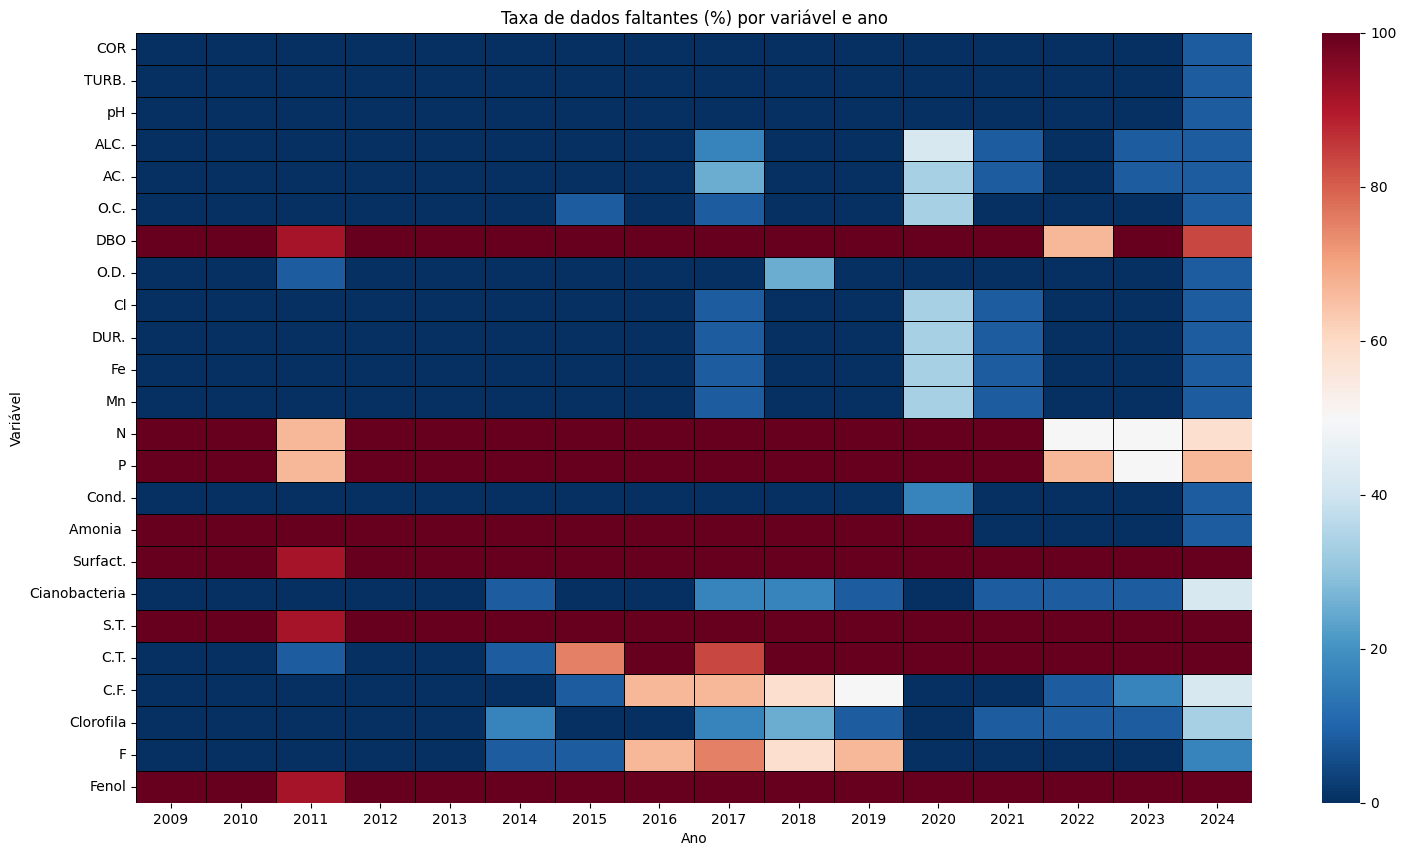

In [9]:
# Só a data e as variáveis: a faltantes_ano desenha como linha toda coluna que não é de data
brutos_med = decompor_estatisticas(brutos, estatistica="med")
faltantes_ano(brutos_med[["Data"] + variaveis_brutos], plot=True, salvar=False)

As figuras do missingno nos brutos (a matriz é a Figura 1 do relatório): na matriz, cada linha é um mês, e cada faixa branca é um valor que falta.

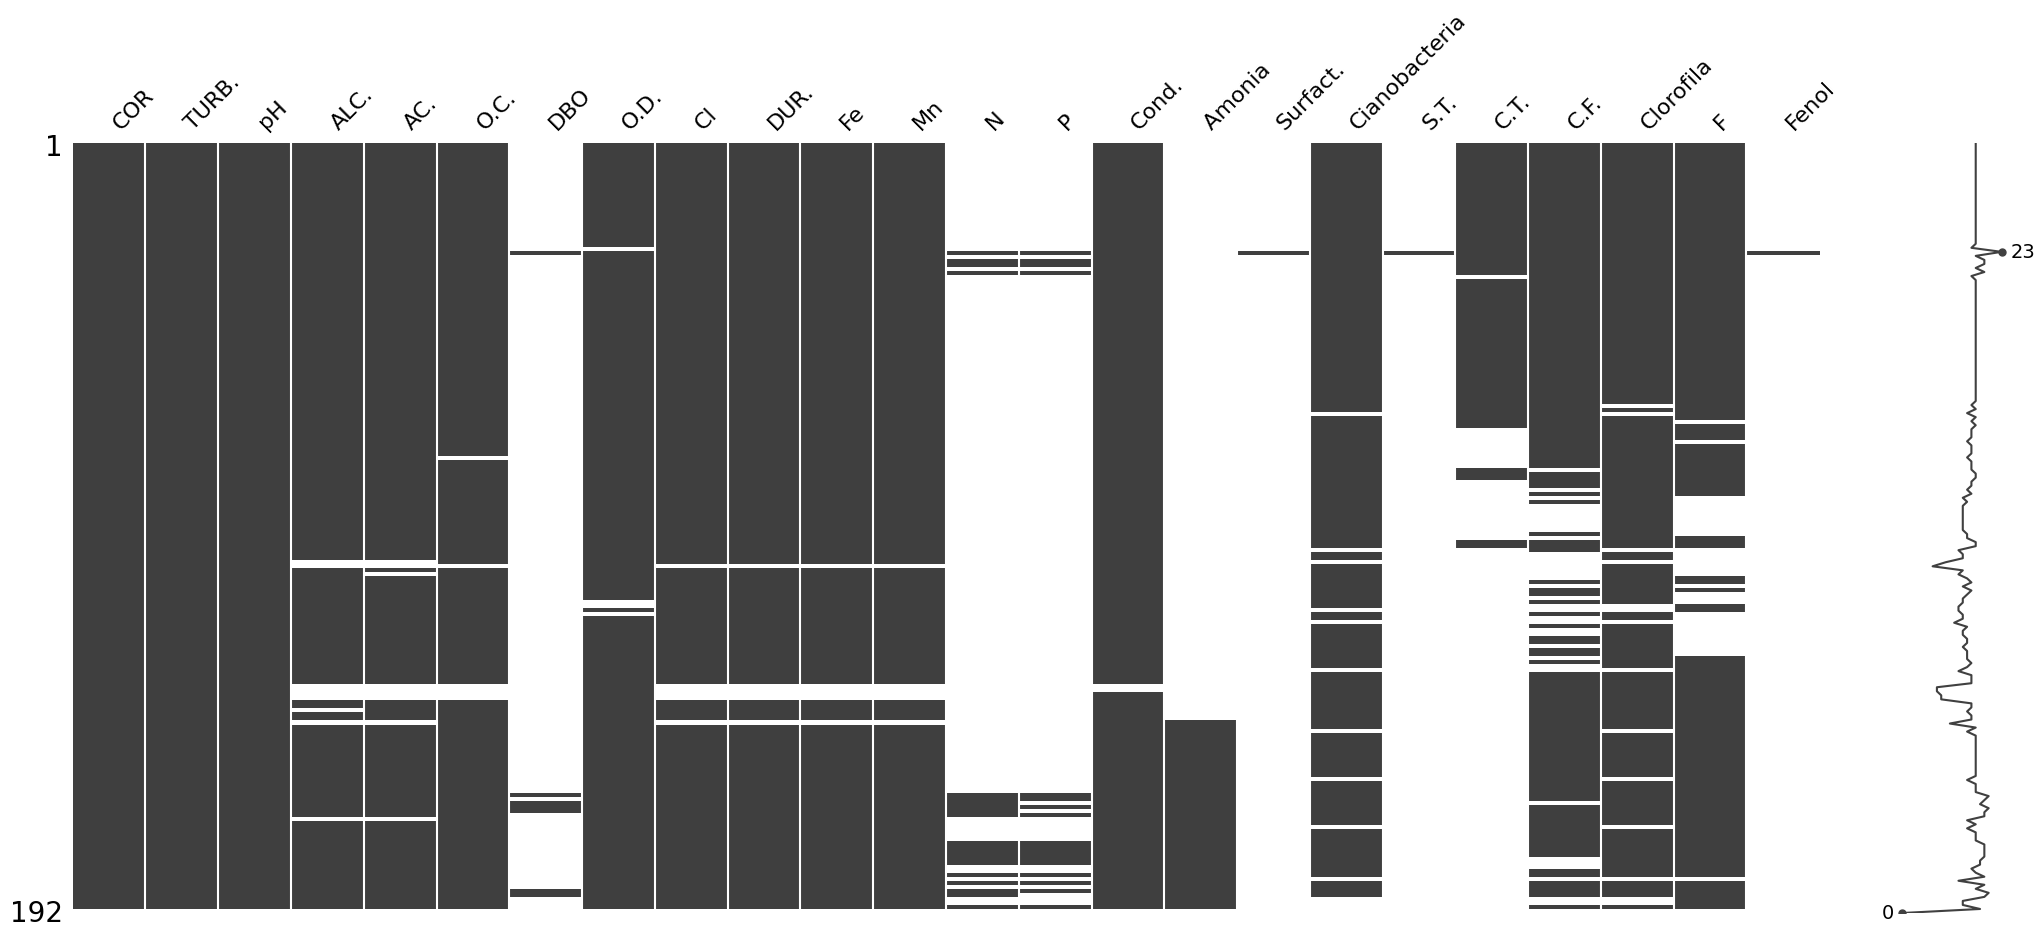

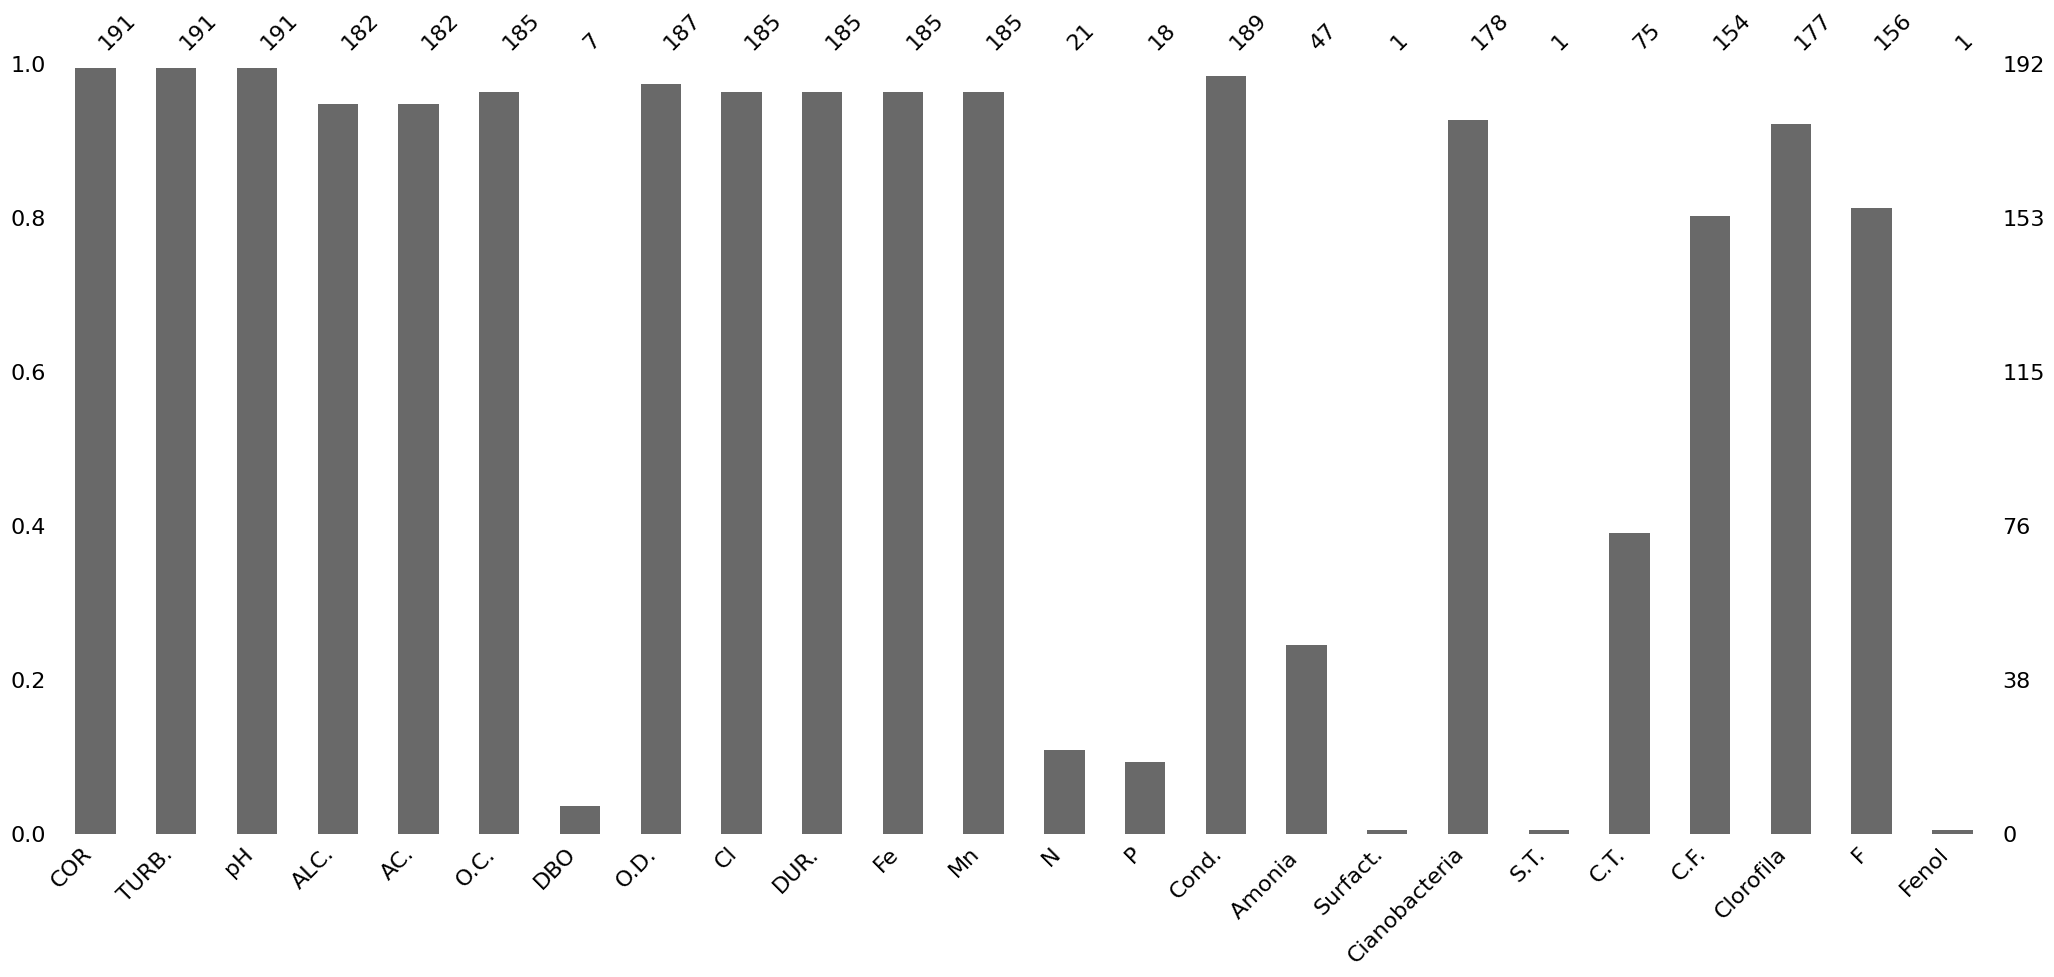

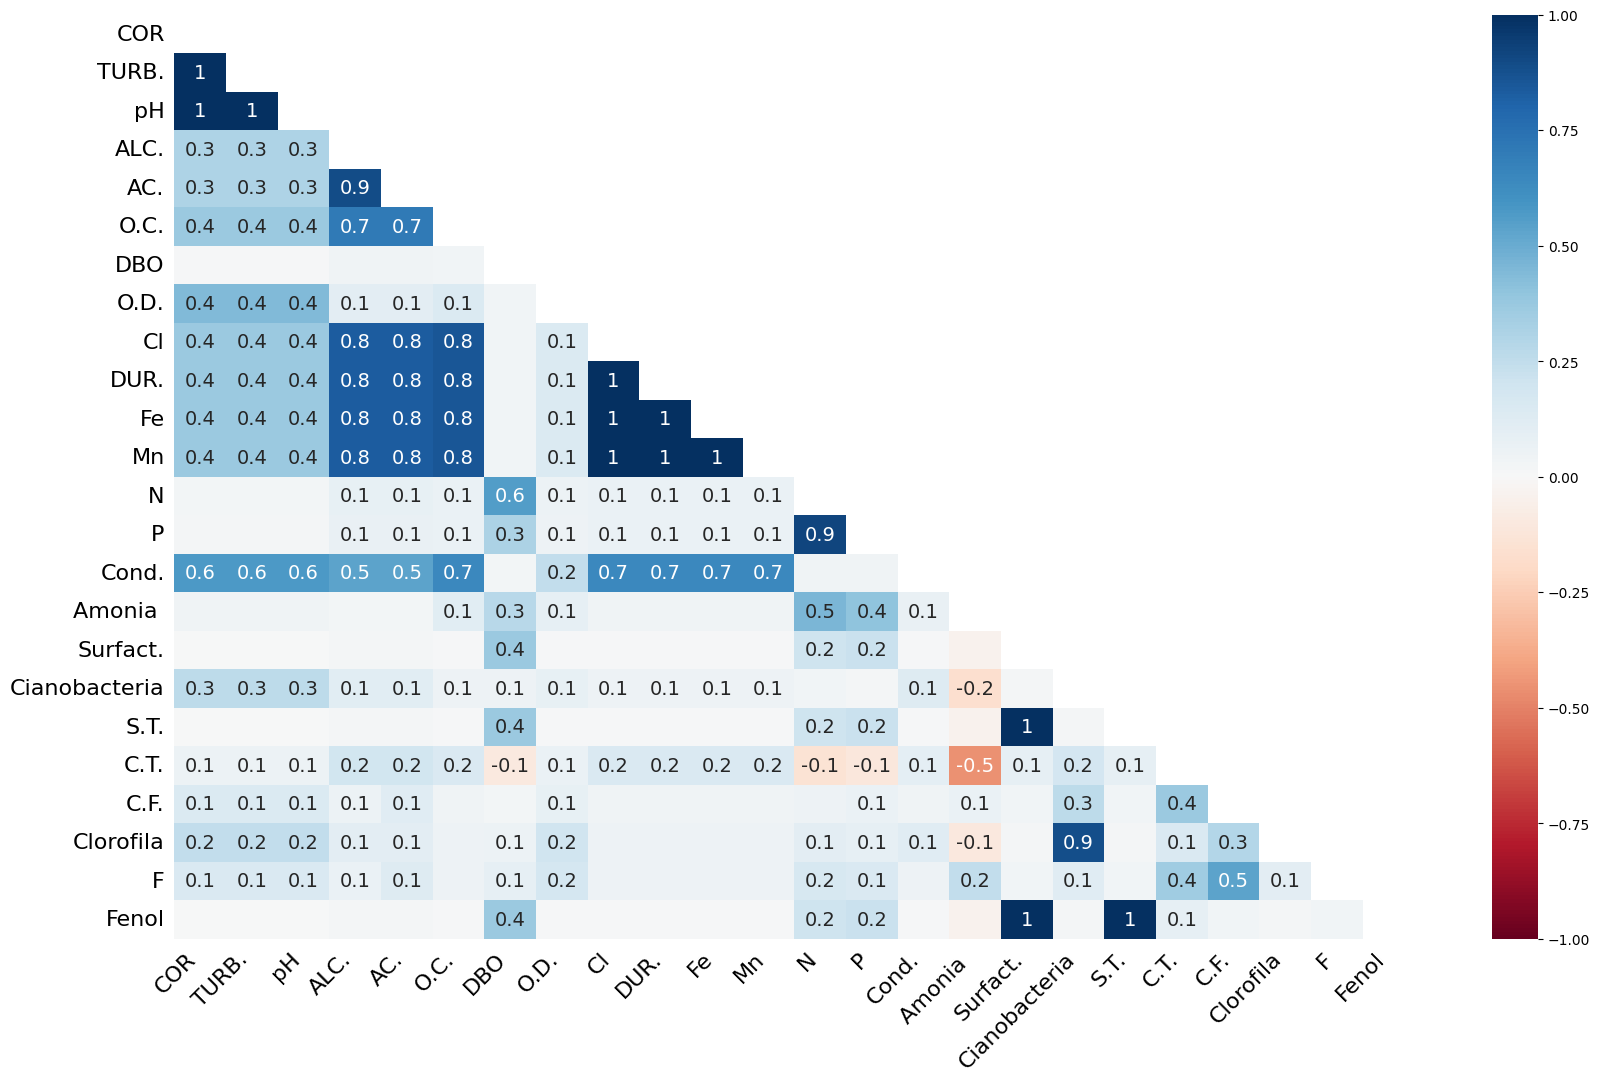

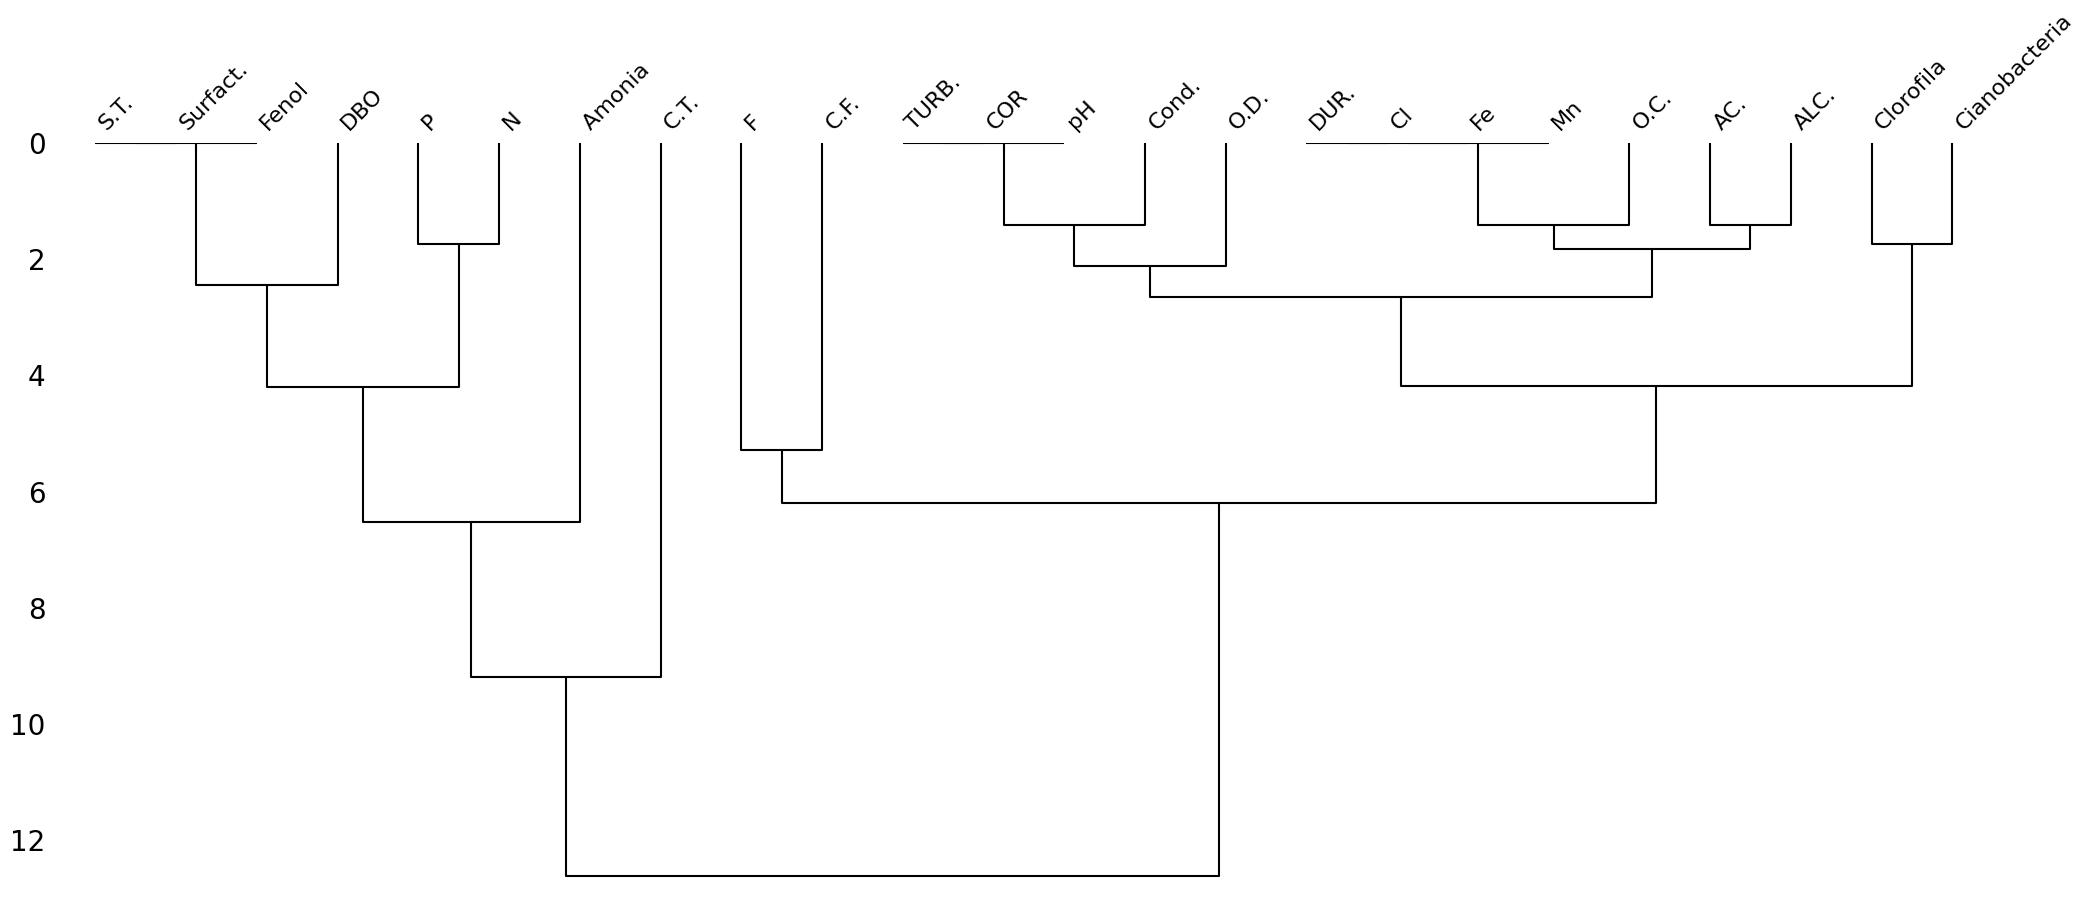

In [10]:
visualizacoes_missingno(brutos_med[variaveis_brutos], plot=True, salvar=False)

## Limpos
Com as 16 variáveis que ficam.

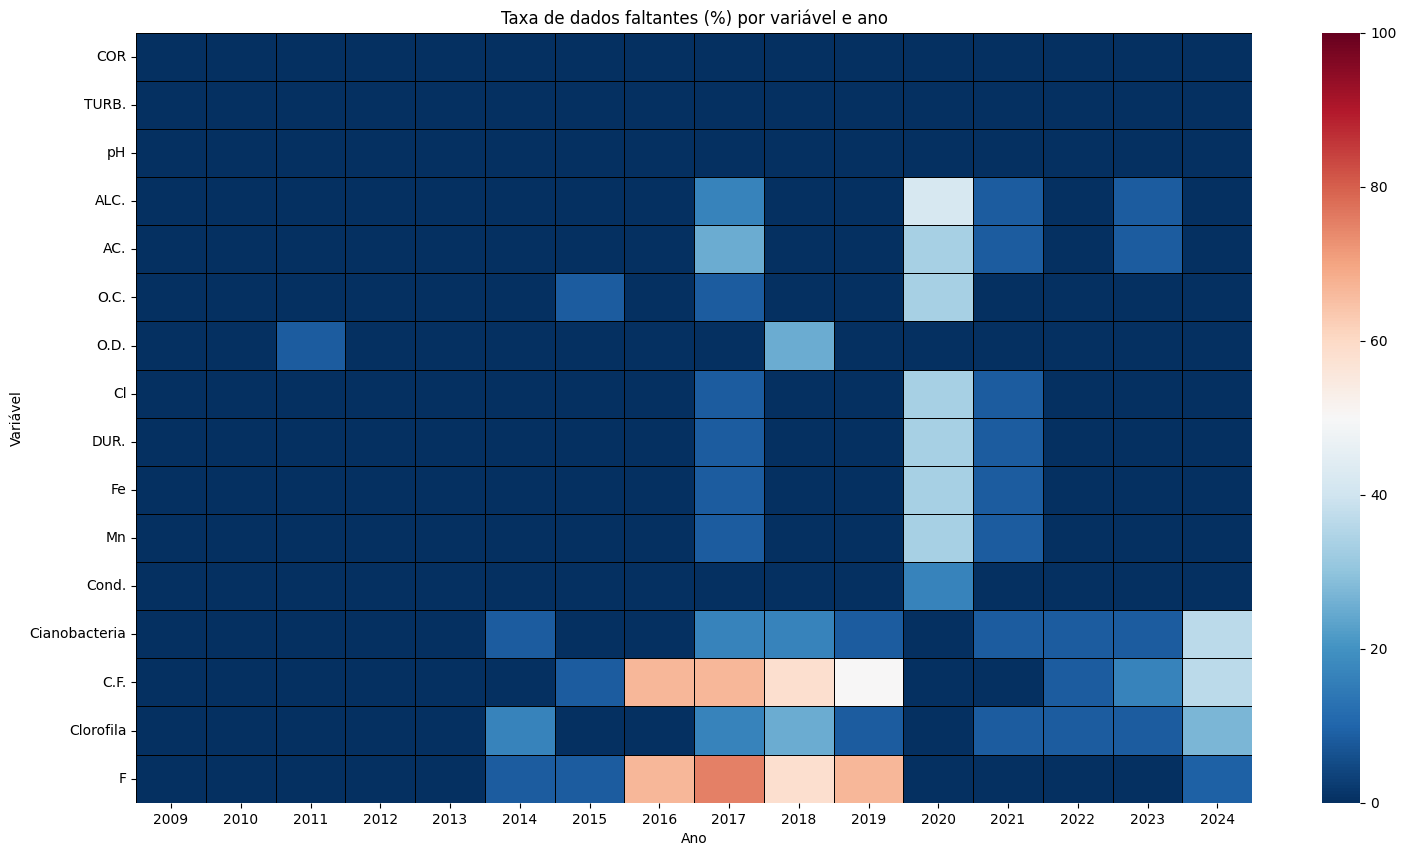

In [11]:
faltantes_ano(decompor_estatisticas(limpos, estatistica="med")[["Data"] + variaveis], plot=True, salvar=False)

## Tratada
Os valores tratados como outliers aparecem como faltantes novos (compare com a figura dos limpos).

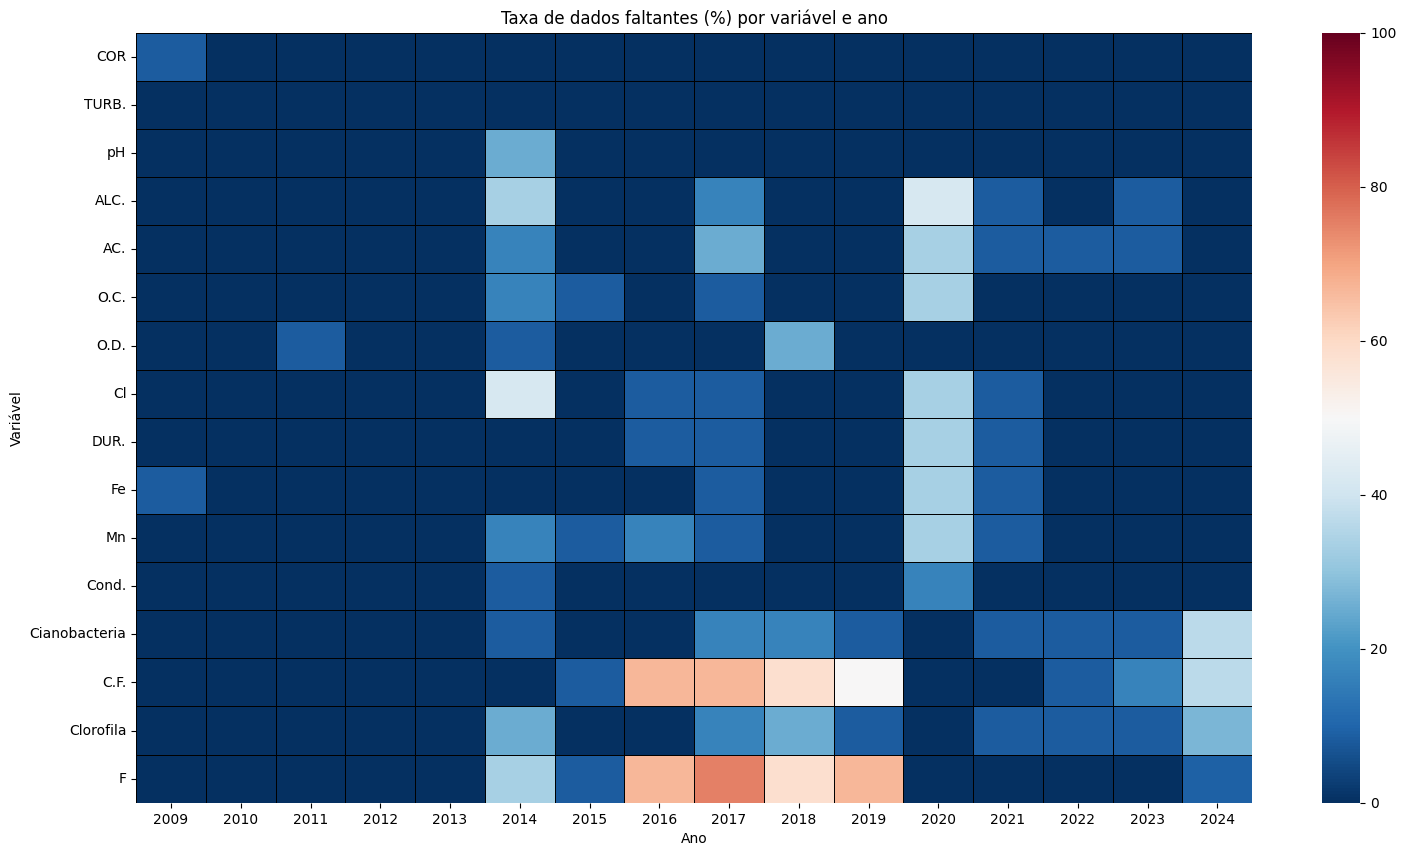

In [12]:
faltantes_ano(tratada[["Data"] + variaveis], plot=True, salvar=False)

# Séries
A média limpa (com os outliers) em linha, mês a mês; as falhas da linha são os meses sem valor. Por cima: os valores tratados como outliers, no valor original (×), e os valores que as duas imputações puseram nas células vazias da tratada.

In [13]:
# Média limpa com o índice de 0 a 190, como na tratada (reset_index), para casar as linhas com ela
media_limpa = decompor_estatisticas(limpos, estatistica="med").reset_index(drop=True)
print("Mesmos meses, na mesma ordem:", (media_limpa["Data"] == tratada["Data"]).all())

# Cada conjunto marcado: a data e as variáveis, com NaN em tudo o que não é marcado
# (where mantém o valor onde a condição é True e põe NaN no resto)
tratados = media_limpa[["Data"] + variaveis].copy()
tratados[variaveis] = media_limpa[variaveis].where(vazias_tratada & media_limpa[variaveis].notna())

imputados_knn = imputada_knn[["Data"] + variaveis].copy()
imputados_knn[variaveis] = imputada_knn[variaveis].where(vazias_tratada)

imputados_pipeline = imputada_pipeline[["Data"] + variaveis].copy()
imputados_pipeline[variaveis] = imputada_pipeline[variaveis].where(vazias_tratada)

print("Marcados: tratados", tratados[variaveis].notna().sum().sum(),
      "| imputados (KNN)", imputados_knn[variaveis].notna().sum().sum(),
      "| imputados (pipeline)", imputados_pipeline[variaveis].notna().sum().sum())

Mesmos meses, na mesma ordem: True
Marcados: tratados 32 | imputados (KNN) 185 | imputados (pipeline) 185


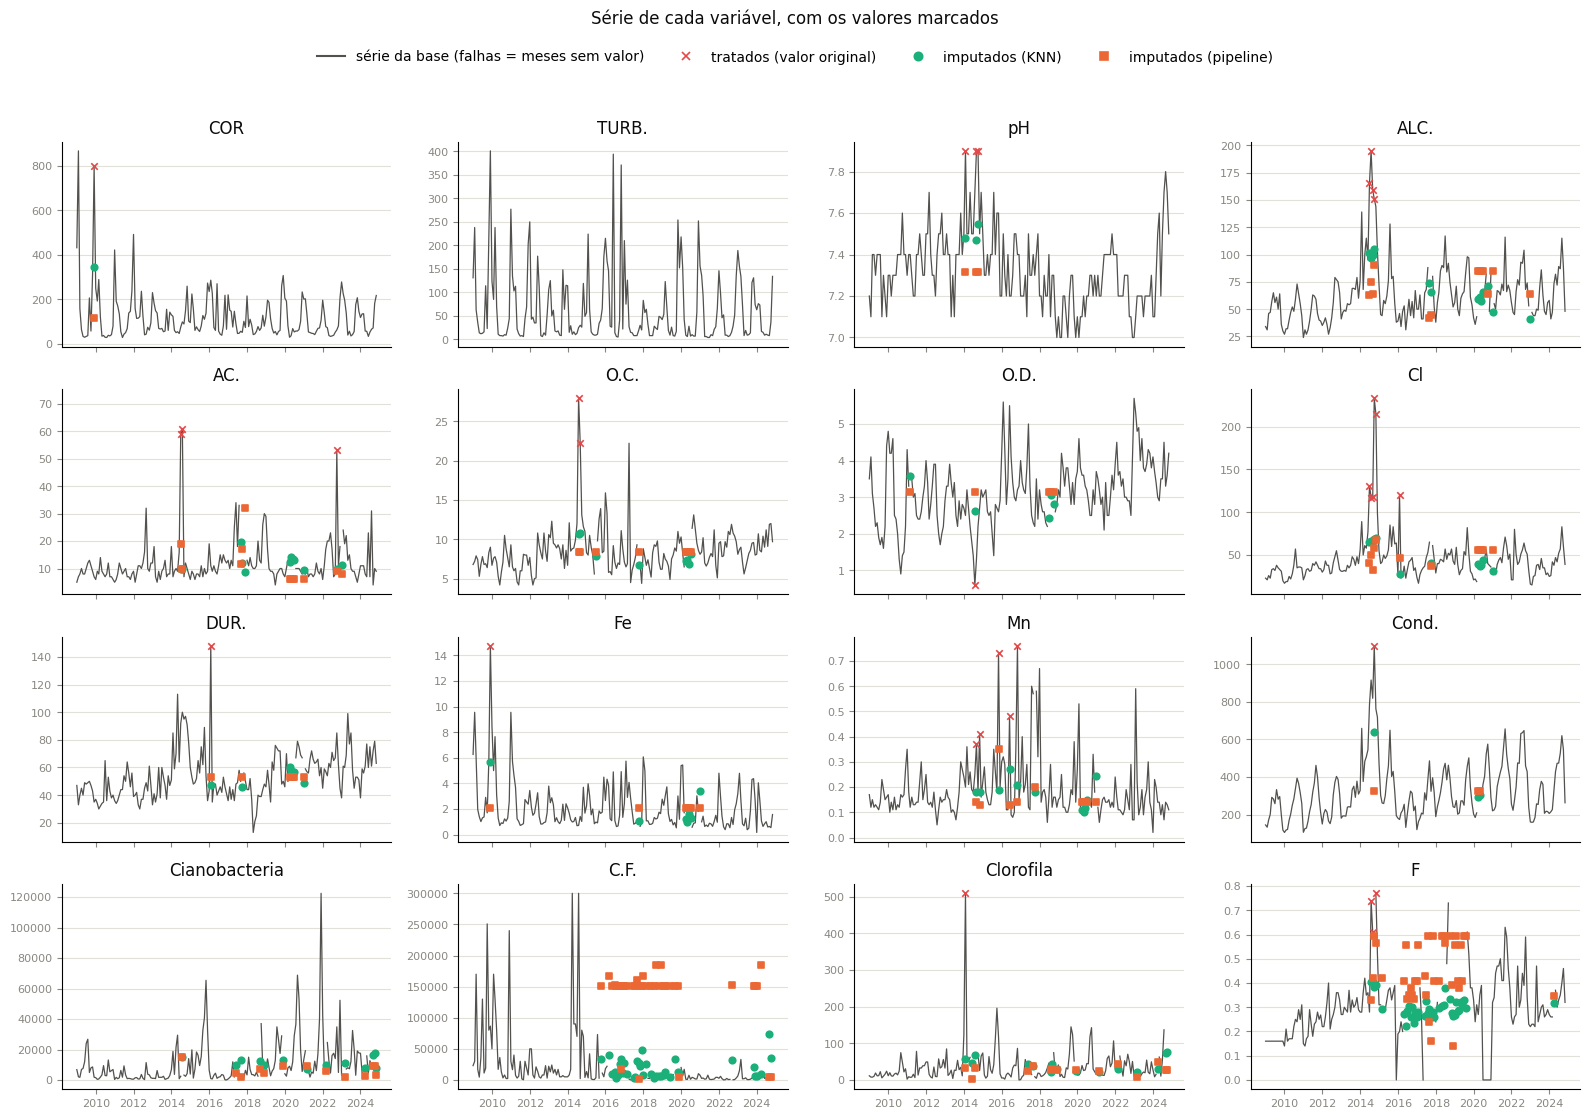

In [14]:
marcas = {"tratados (valor original)": tratados, "imputados (KNN)": imputados_knn,
          "imputados (pipeline)": imputados_pipeline}
series_marcadas(media_limpa, marcas, variaveis=variaveis, plot=True, salvar=False)

# Boxplots
A distribuição de cada variável em cada etapa da média: limpos (com os outliers), tratada e as duas imputadas. Os brutos não têm caixa própria: nas 16 variáveis, a média dos brutos é igual à dos limpos (conferido abaixo).

Os pontos soltos são os valores além de 1,5 × IQR (a regra do próprio boxplot), e não os outliers tratados. O tratamento usou o ensemble e a regra valor a valor (notebook `outliers`), que mudaram bem menos valores do que o boxplot deixa de fora. Por isso, muitos pontos continuam soltos na tratada.

In [15]:
# Conferência: a média dos brutos é a mesma dos limpos nas 16 variáveis, nos 191 meses dos limpos.
# Os meses são casados pela data; o que for texto nos brutos vira NaN, como na limpeza
media_brutos = brutos_med.set_index("Data")[variaveis].apply(pd.to_numeric, errors="coerce")
media_limpos = media_limpa.set_index("Data")[variaveis]
media_brutos = media_brutos.loc[media_limpos.index]
print("Maior diferença:", (media_brutos - media_limpos).abs().max().max(),
      "| as mesmas células vazias:", (media_brutos.isna() == media_limpos.isna()).all().all())

Maior diferença: 0.0 | as mesmas células vazias: True


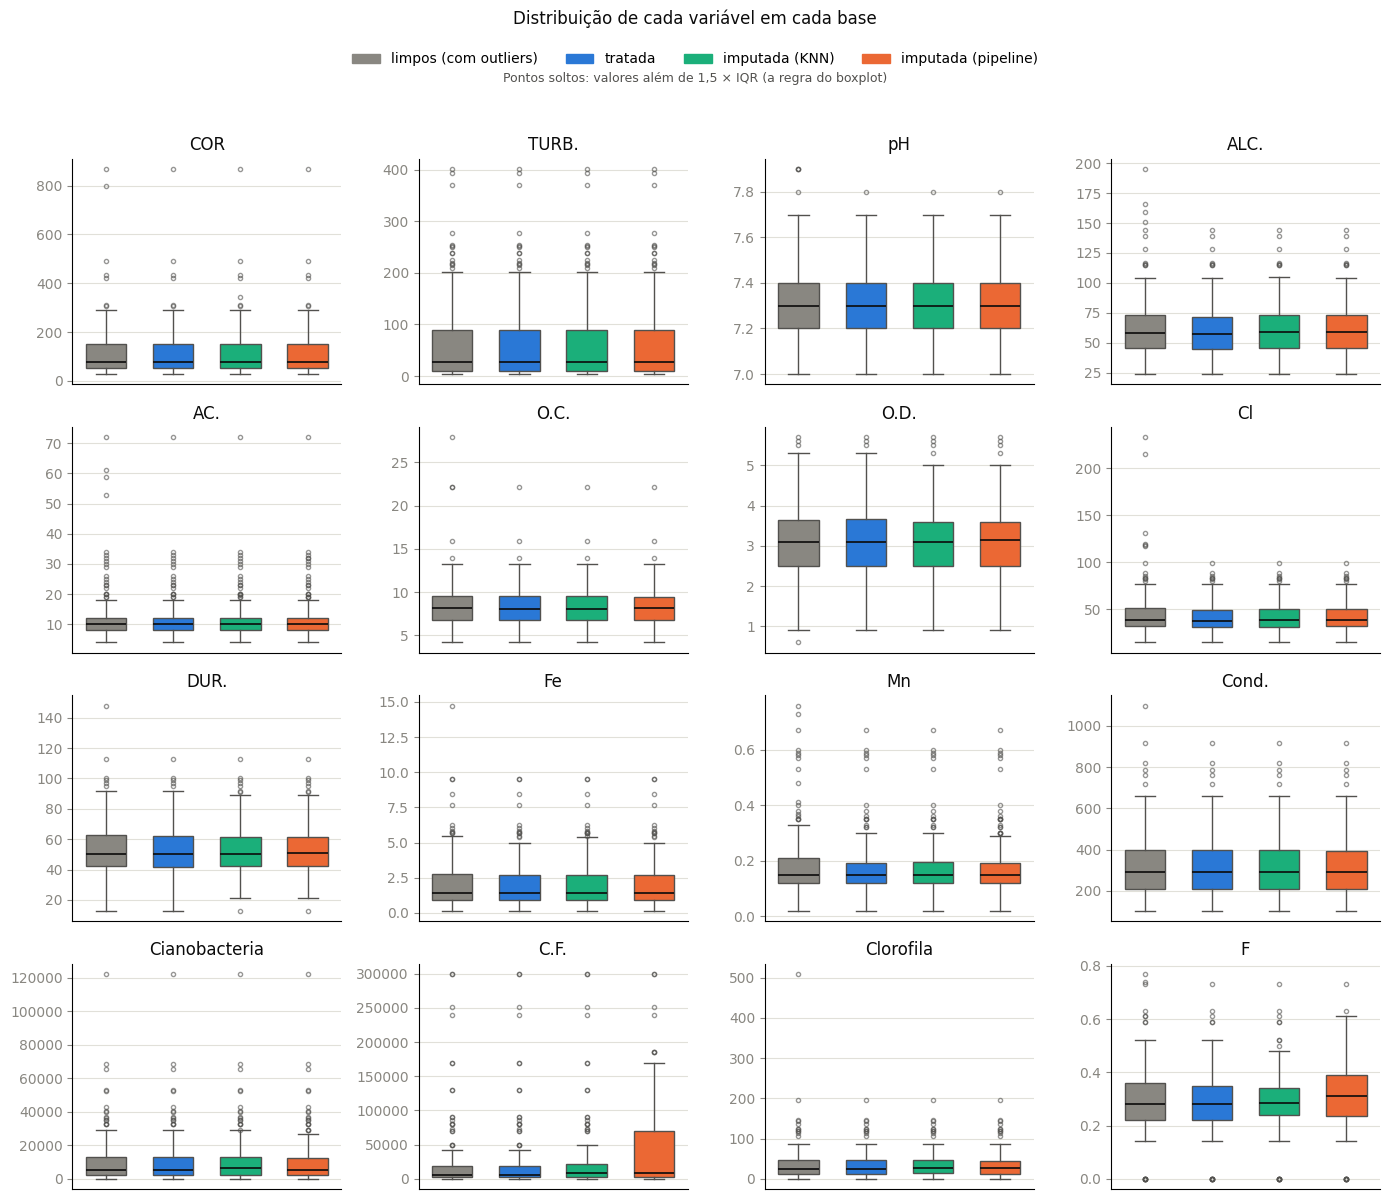

In [16]:
bases_boxplot = {"limpos (com outliers)": media_limpa, "tratada": tratada,
                 "imputada (KNN)": imputada_knn, "imputada (pipeline)": imputada_pipeline}
boxplots_bases(bases_boxplot, variaveis=variaveis, plot=True, salvar=False)

# Gravação
- `data/processed/dados_med_imputados_knn.xlsx` e `dados_med_imputados_pipeline.xlsx`: as bases completas, com as mesmas colunas da tratada (nome fixo, como a `dados_med_tratados.xlsx`);
- `data/output/descritiva_evolutiva.xlsx`: abas `resumo` e `analise_descritiva` (os 9 quadros, com as colunas `base` e `estatistica`).

Rodar de novo dá os mesmos números: nenhuma etapa tem sorteio.

In [17]:
imputada_knn.to_excel(BASE_DIR / "data" / "processed" / "dados_med_imputados_knn.xlsx", index=False)
imputada_pipeline.to_excel(BASE_DIR / "data" / "processed" / "dados_med_imputados_pipeline.xlsx", index=False)

caminho = BASE_DIR / "data" / "output" / "descritiva_evolutiva.xlsx"

# ExcelWriter permite gravar várias abas no mesmo arquivo
with pd.ExcelWriter(caminho) as arquivo:
    resumo.to_excel(arquivo, sheet_name="resumo", index=False)
    analise.to_excel(arquivo, sheet_name="analise_descritiva", index=False)

print("Gravado em:", caminho)

Gravado em: C:\_Master\Programacao\Guilherme-Betta\1_Projects\IC2\IC2-item-6\data\output\descritiva_evolutiva.xlsx
